In [1]:
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split

# 读取训练数据
df = pd.read_csv("../data/train.csv")

# 划分特征和目标变量
X = df.drop(columns=["id", "Churn"])
y = (df["Churn"] == "Yes").astype(int)

# 划分训练集与验证集
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("训练集：", X_train.shape)
print("验证集：", X_valid.shape)
print("训练集流失率：", round(y_train.mean(), 4))
print("验证集流失率：", round(y_valid.mean(), 4))

训练集： (475355, 19)
验证集： (118839, 19)
训练集流失率： 0.2252
验证集流失率： 0.2252


In [2]:
# 找出类别变量
cat_cols = X_train.select_dtypes(include=["object", "str"]).columns

# 将类别变量转换为 category 类型
for col in cat_cols:
    X_train[col] = X_train[col].astype("category")
    X_valid[col] = pd.Categorical(
        X_valid[col],
        categories=X_train[col].cat.categories
    )

print("类别变量数量：", len(cat_cols))
print(X_train.dtypes)

类别变量数量： 15
gender              category
SeniorCitizen          int64
Partner             category
Dependents          category
tenure                 int64
PhoneService        category
MultipleLines       category
InternetService     category
OnlineSecurity      category
OnlineBackup        category
DeviceProtection    category
TechSupport         category
StreamingTV         category
StreamingMovies     category
Contract            category
PaperlessBilling    category
PaymentMethod       category
MonthlyCharges       float64
TotalCharges         float64
dtype: object


In [3]:
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

# 1. 初始化 LightGBM 模型
lgb_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    random_state=42,
    verbosity=-1,
    n_jobs=-1
)

# 2. 训练模型
lgb_model.fit(
    X_train,
    y_train,
    categorical_feature=list(cat_cols)
)

# 3. 预测训练集与验证集的流失概率
y_train_proba = lgb_model.predict_proba(X_train)[:, 1]
y_valid_proba = lgb_model.predict_proba(X_valid)[:, 1]

# 4. 计算 ROC-AUC
train_auc = roc_auc_score(y_train, y_train_proba)
valid_auc = roc_auc_score(y_valid, y_valid_proba)

print(f"训练集 ROC-AUC: {train_auc:.4f}")
print(f"验证集 ROC-AUC: {valid_auc:.4f}")
print(f"AUC 差值: {train_auc - valid_auc:.4f}")

训练集 ROC-AUC: 0.9183
验证集 ROC-AUC: 0.9160
AUC 差值: 0.0024


In [4]:
import numpy as np
import pandas as pd

# 按 LightGBM 预测风险从高到低排序
ranking = pd.DataFrame({
    "y_true": np.asarray(y_valid),
    "risk_score": y_valid_proba
}).sort_values("risk_score", ascending=False)

total_churn = ranking["y_true"].sum()
n = len(ranking)

results = []

for ratio in [0.1, 0.2, 0.3]:
    k = int(n * ratio)
    selected = ranking.head(k)

    tp = selected["y_true"].sum()

    results.append({
        "Budget Ratio": ratio,
        "Contacted": k,
        "True Churn": tp,
        "Precision@K": tp / k,
        "Recall@K": tp / total_churn,
        "Lift@K": (tp / k) / (total_churn / n)
    })

lgb_budget_df = pd.DataFrame(results)

lgb_budget_df.round(4)

,Budget Ratio,Contacted,True Churn,Precision@K,Recall@K,Lift@K
0,0.1,11883,9859,0.8297,0.3684,3.6841
1,0.2,23767,16958,0.7135,0.6336,3.1683
2,0.3,35651,21804,0.6116,0.8147,2.7157


             Feature  Importance
18      TotalCharges        2353
4             tenure        1936
17    MonthlyCharges        1886
14          Contract         433
16     PaymentMethod         287
6      MultipleLines         255
1      SeniorCitizen         226
15  PaperlessBilling         197
3         Dependents         173
8     OnlineSecurity         169
12       StreamingTV         165
13   StreamingMovies         160
7    InternetService         153
11       TechSupport         110
2            Partner         106


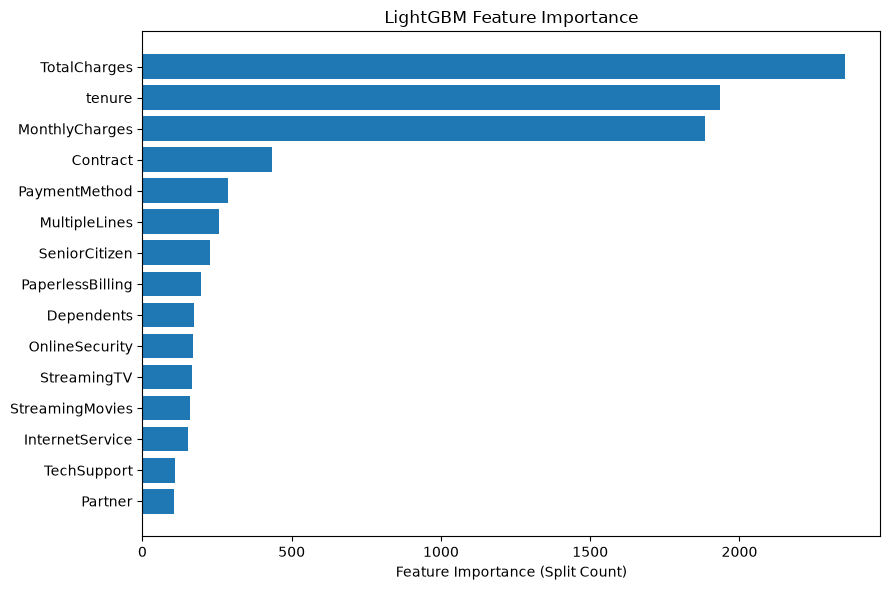

In [5]:
import matplotlib.pyplot as plt

# 提取特征重要性
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": lgb_model.feature_importances_
}).sort_values("Importance", ascending=False)

# 显示前 15 个特征
print(importance_df.head(15))

# 绘制特征重要性图
plt.figure(figsize=(9, 6))

plt.barh(
    importance_df["Feature"].head(15)[::-1],
    importance_df["Importance"].head(15)[::-1]
)

plt.xlabel("Feature Importance (Split Count)")
plt.title("LightGBM Feature Importance")
plt.tight_layout()
plt.show()

In [6]:
# 提取 Gain Importance
gain_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Gain": lgb_model.booster_.feature_importance(
        importance_type="gain"
    )
}).sort_values("Gain", ascending=False)

# 计算各特征占总 Gain 的比例
gain_importance["Gain (%)"] = (
    gain_importance["Gain"]
    / gain_importance["Gain"].sum()
    * 100
)

gain_importance.head(15).round(2)

,Feature,Gain,Gain (%)
14,Contract,1147438.02,49.29
7,InternetService,311975.69,13.40
16,PaymentMethod,299591.84,12.87
4,tenure,283566.67,12.18
17,MonthlyCharges,71589.34,3.08
18,TotalCharges,45980.95,1.98
8,OnlineSecurity,40518.30,1.74
15,PaperlessBilling,22532.58,0.97
12,StreamingTV,19585.96,0.84
1,SeniorCitizen,18128.90,0.78


In [7]:
from sklearn.inspection import permutation_importance

# 为控制运行时间，固定抽取 10000 条验证样本
X_sample = X_valid.sample(n=10000, random_state=42)
y_sample = y_valid.loc[X_sample.index]

# 计算置换重要性
perm_result = permutation_importance(
    lgb_model,
    X_sample,
    y_sample,
    scoring="roc_auc",
    n_repeats=3,
    random_state=42,
    n_jobs=1
)

perm_df = pd.DataFrame({
    "Feature": X_sample.columns,
    "AUC Drop": perm_result.importances_mean,
    "Std": perm_result.importances_std
}).sort_values("AUC Drop", ascending=False)

perm_df.round(4)

,Feature,AUC Drop,Std
14,Contract,0.0945,0.0019
4,tenure,0.0638,0.0029
18,TotalCharges,0.0232,0.0003
7,InternetService,0.0153,0.0006
16,PaymentMethod,0.0071,0.0005
17,MonthlyCharges,0.0043,0.0007
15,PaperlessBilling,0.0026,0.0002
6,MultipleLines,0.0020,0.0001
12,StreamingTV,0.0020,0.0001
8,OnlineSecurity,0.0016,0.0002
